In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
from joblib import Parallel, delayed
%matplotlib inline

figures_path = 'figures/'
palette = plt.rcParams['axes.prop_cycle'].by_key()['color']  

In [2]:
def diff_assump(parameters, state_var, dt , elong_fun):

    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes, separate pool for each
    y_free = parameters['Y_max'] - np.sum(y_vec) 


    new_x_vec = x_vec + dt * (-parameters['α']  * r * x_vec  + parameters['β']* xr_vec * y_free)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec * y_free)
    new_y_vec = y_vec + dt * (parameters['β']  * xr_vec * y_free - parameters['γ'] * y_vec)
    #reinitiation

    return new_x_vec, new_xr_vec, new_y_vec

def TASEP_assump(parameters, state_var, dt , elong_fun):

    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes, separate pool for each
    y_free = parameters['Y_max'] - np.sum(y_vec) 


    new_x_vec = x_vec + dt * (-(parameters['α'] + 1/elong_fun(parameters['l'],parameters['lp'], xr_vec))   * r * x_vec  + parameters['β']* xr_vec * y_free)
    new_xr_vec = xr_vec + dt * ((parameters['α']+ 1/elong_fun(parameters['l'],parameters['lp'], xr_vec)) * r *  x_vec - parameters['β'] * xr_vec * y_free)
    new_y_vec = y_vec + dt * (parameters['β']  * xr_vec * y_free - parameters['γ'] * y_vec)
    #reinitiation

    return new_x_vec, new_xr_vec, new_y_vec


def simulation_wrapper(params, sim_time, dt, Rs): 
    
    parameters = dict()
    parameters['α'] = params[0]
    parameters['β'] = params[1] / l_samples
    parameters['γ'] = γ
    parameters['l'] = l_samples
    parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)
    parameters['Y_max'] =  N
    res = np.zeros([Rs.shape[0],3,N ])
    
    for r in range(Rs.shape[0]): 
        parameters['R'] = Rs[r]


        x0 = np.ones([N])*x_init
        init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 

        next_t = init_state

        for t in range(int(sim_time/dt)):
            next_t = model_assump(parameters, next_t, dt, R_fernandes)
        res[r] = next_t

    return res

Here we test the influence of the overall setting of alpha and beta for the competition.
We reduce number of species show the effect clearly and can translate it better to the analytical results. 

In [3]:
α_samples = np.linspace(0.0001, 0.1, 10) #this ensures that we will have cases in which α < β
β_samples = np.linspace(0.0001, 0.1, 8)

In [4]:
sim_time = 100 #this might be varied per simulation as we need to make sure all simulation reach their steady state
sampling = 100

results = Parallel(n_jobs=-1)(delayed(simulation_wrapper)([a,b], sim_time, dt,Rs) for a in α_samples for b in β_samples)
results = np.asarray(results)

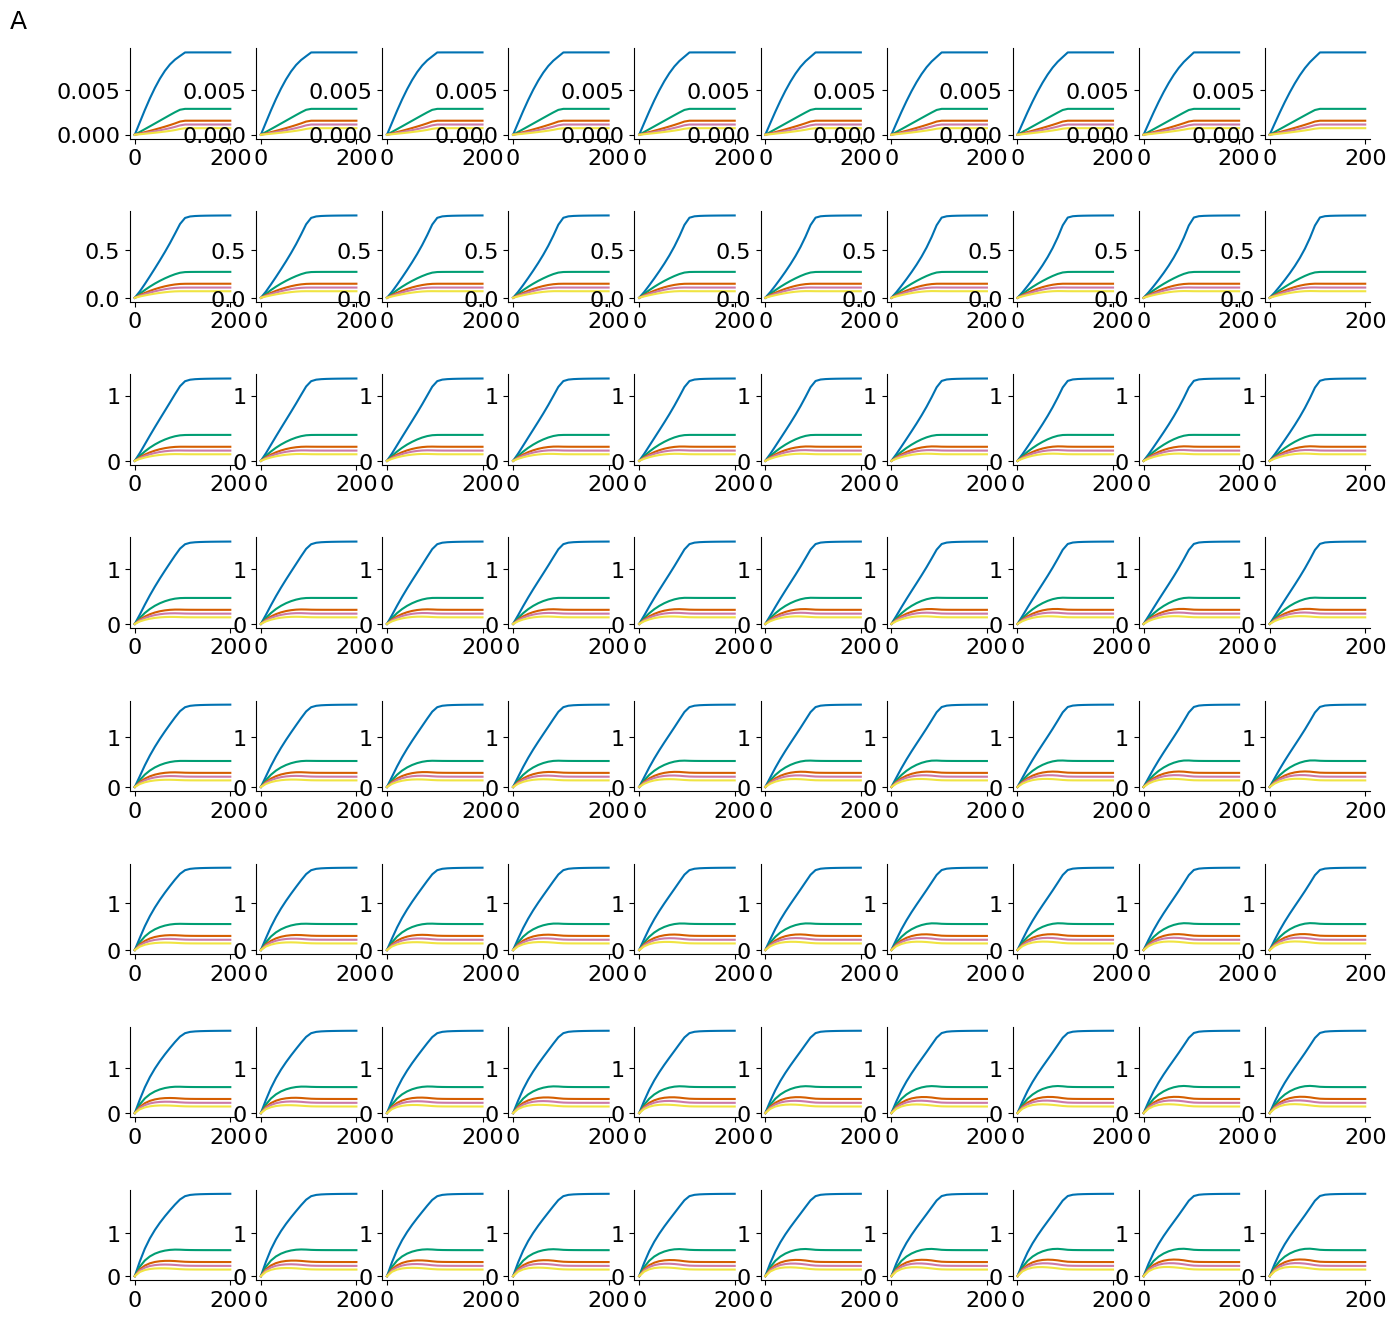

In [5]:
layout = '''
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    '''

fig = plt.figure(figsize=(16, 16))

height_ratios = [1,1,1,1,1,1,1,1]
width_ratios = [1,1,1,1,1,1,1,1,1,1]

specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'A':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='A', postfix='', offset_left=1.2)
for a in list('A'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
for i in range(α_samples.shape[0]):
    for j in range(β_samples.shape[0]): 
        
        ax = fig.add_subplot(gs[j,i])
        av1 = np.mean(results[i * β_samples.shape[0] +j,:, 2,s_1k], axis = 0)
        av2 = np.mean(results[i * β_samples.shape[0] +j,:, 2,s_2k], axis = 0)
        av3 = np.mean(results[i * β_samples.shape[0] +j,:, 2,s_3k], axis = 0)
        av4 = np.mean(results[i * β_samples.shape[0] +j,:, 2,s_4k], axis = 0)
        av5 = np.mean(results[i * β_samples.shape[0] +j,:, 2,b_4k], axis = 0)

        ax.plot(Rs, av1, label = '<1k')
        ax.plot(Rs, av2, label = '1-2k')
        ax.plot(Rs, av3, label = '2-3k')
        ax.plot(Rs, av4, label = '3-4k')
        ax.plot(Rs, av5, label = '>4k')

        clear_axes(ax)
    
plt.show()



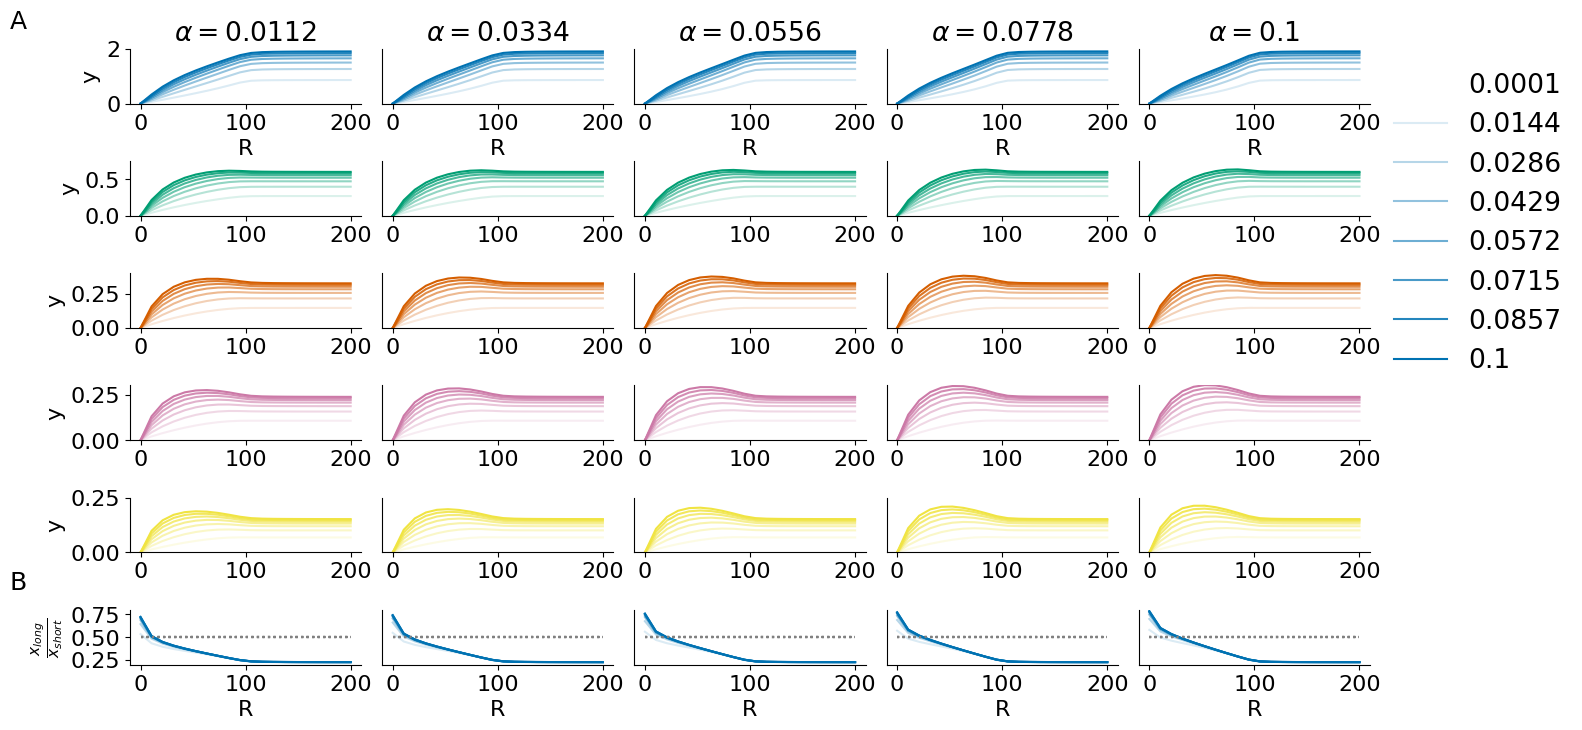

In [27]:
layout = '''
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    BBBBBBBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1,0.1,1,0.1,1,0.1,1,0.1,1]
width_ratios = [1,1,1,1,1,1,1,1,1,1]

specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
avs = np.linspace(0,1, β_samples.shape[0])

 
for i in range(1,α_samples.shape[0],2):
    ax1 = fig.add_subplot(gs[0,i-1:i+2-1])
    ax2 = fig.add_subplot(gs[2,i-1:i+2-1])
    ax3 = fig.add_subplot(gs[4,i-1:i+2-1])
    ax4 = fig.add_subplot(gs[6,i-1:i+2-1])
    ax5 = fig.add_subplot(gs[8,i-1:i+2-1])
    ax = fig.add_subplot(gs[10,i-1:i+2-1])
    for j in range(0,β_samples.shape[0]):
        av1 = np.mean(results[i * β_samples.shape[0] +j,:, 2,s_1k], axis = 0)
        av2 = np.mean(results[i * β_samples.shape[0] +j,:, 2,s_2k], axis = 0)
        av3 = np.mean(results[i * β_samples.shape[0] +j,:, 2,s_3k], axis = 0)
        av4 = np.mean(results[i * β_samples.shape[0] +j,:, 2,s_4k], axis = 0)
        av5 = np.mean(results[i * β_samples.shape[0] +j,:, 2,b_4k], axis = 0)
        
        rat1 = np.mean(results[i * β_samples.shape[0] +j,:, 2,long_ind], axis = 0)/np.mean(results[i * β_samples.shape[0] +j,:, 2,short_ind], axis = 0)

        ax1.plot(Rs, av1, label = np.round(β_samples[j],4), color= palette[0], alpha = avs[j])
        ax2.plot(Rs, av2, label = β_samples[j], color = palette[1], alpha = avs[j])
        ax3.plot(Rs, av3, label = β_samples[j], color = palette[2], alpha = avs[j])
        ax4.plot(Rs, av4, label = β_samples[j], color = palette[3], alpha = avs[j])
        ax5.plot(Rs, av5, label = β_samples[j], color =palette[4], alpha = avs[j])
        ax.plot(Rs, rat1, label = β_samples[j], color = palette[0], alpha = avs[j])
        ax.plot(Rs, Rs*0 + 0.5, linestyle = ':', color = 'grey')
    ax1.set_title('$\\alpha =$'+str(np.round(α_samples[i],4)))
    ax1.set_ylim(0,2)
    ax2.set_ylim(0,0.75)
    ax3.set_ylim(0,0.4)
    ax4.set_ylim(0,0.3)
    ax5.set_ylim(0,0.25)
    ax.set_ylim(0.2,0.8)
    ax1.set_xlabel('R')
    ax.set_xlabel('R')
    
    if (i-1) > 0: 
        ax.set_yticks([])
        ax1.set_yticks([])
        ax2.set_yticks([])
        ax3.set_yticks([])
        ax4.set_yticks([])
        ax5.set_yticks([])
    else: 
        ax1.set_ylabel('y')
        ax2.set_ylabel('y')
        ax3.set_ylabel('y')
        ax4.set_ylabel('y')
        ax5.set_ylabel('y')
        ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
    

    clear_axes(ax)
    clear_axes(ax1)
    clear_axes(ax2)
    clear_axes(ax3)
    clear_axes(ax4)
    clear_axes(ax5)
handles, labels = ax.get_legend_handles_labels()
ax1.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
plt.savefig('fig5_parameter_exploration.pdf')      
plt.show()

